In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(
    "COVID-19BehaviorData_CAN2022.csv",
    low_memory=False)

# Convert whitespace-only cells to missing values
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Shape:", df.shape)
print(df.info())
print(df.head())

# Count fully missing columns
print("Empty columns:", df.isna().all().sum())

Shape: (6430, 512)
<class 'pandas.DataFrame'>
RangeIndex: 6430 entries, 0 to 6429
Columns: 512 entries, RecordNo to future_3
dtypes: float64(1), int64(3), str(508)
memory usage: 25.1 MB
None
   RecordNo           endtime    qweek i1_health i2_health i7a_health  \
0     41589  06/01/2022 18:02  week 44       NaN         0        NaN   
1     41731  03/01/2022 23:48  week 44       NaN         1        NaN   
2     41756  10/01/2022 04:53  week 44       NaN         0        NaN   
3     41846  01/01/2022 13:15  week 44       NaN         5        NaN   
4     41847  01/01/2022 19:12  week 44       NaN       150        NaN   

  i3_health i4_health i5_health_1 i5_health_2  ... vac_man_96 vac_man_99  \
0       NaN       NaN         NaN         NaN  ...         No         No   
1       NaN       NaN         NaN         NaN  ...         No         No   
2       NaN       NaN         NaN         NaN  ...        Yes         No   
3       NaN       NaN         NaN         NaN  ...         No     

### Data Preprocessing

In [3]:
#Delete blank columns
df_clean = df.dropna(axis=1, how="all").copy()

print("New shape:", df_clean.shape)

missing_summary = (
    df_clean.isna().mean() * 100).sort_values(ascending=False)

print(missing_summary.head(30))

New shape: (6430, 159)
vac12_4       89.984448
vac12_3       89.984448
vac12_12      89.984448
vac12_96      89.984448
vac12_10      89.984448
vac12_9       89.984448
vac12_8       89.984448
vac12_7       89.984448
vac12_6       89.984448
vac12_5       89.984448
vac12_11      89.984448
vac12_13      89.984448
vac12_2       89.984448
vac12_1       89.984448
vac_1         89.984448
long_covid    87.636081
WAH_1         85.427683
WAH_3         85.427683
WAH_2         85.427683
Soc2_1        85.054432
Soc2_2        85.054432
Soc2_3        85.054432
Soc2_4        85.054432
Soc2_5        85.054432
Soc2_6        85.054432
had_covid     84.898911
future_3      84.432348
travel1_4     74.634526
Vent_1        74.634526
travel1_1     74.634526
dtype: float64


**Dataset includes lots of missing value. The missing rate of remaining variables varies a lot.**

In [4]:
##Define the target variable, here we choose the vaccination status (vac)
# Examine the target variable
print(df_clean["vac"].value_counts(dropna=False))

print(
    df_clean["vac"].value_counts(normalize=True) * 100)


vac
Yes, two doses    5559
No, neither        644
Yes, one dose      227
Name: count, dtype: int64
vac
Yes, two doses    86.454121
No, neither       10.015552
Yes, one dose      3.530327
Name: proportion, dtype: float64


In [5]:
#Create binary target variable
df_clean["vac_binary"] = df_clean["vac"].map({
    "Yes, two doses": 1,
    "Yes, one dose": 0,
    "No, neither": 0})

# Check the distribution
print(df_clean["vac_binary"].value_counts())
print(df_clean["vac_binary"].value_counts(normalize=True) * 100)

# Check for missing target values
print("Missing target:", df_clean["vac_binary"].isna().sum())


vac_binary
1    5559
0     871
Name: count, dtype: int64
vac_binary
1    86.454121
0    13.545879
Name: proportion, dtype: float64
Missing target: 0


In [6]:
##Predictor Selection
# Inspect available variables for predictor selection
variable_summary = pd.DataFrame({
    "Variable": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Missing (%)": (
        df_clean.isna().mean().values * 100
    ).round(2),
    "Unique Values": df_clean.nunique().values
})

# Exclude the newly created target from candidate predictors
variable_summary = variable_summary[
    ~variable_summary["Variable"].isin(
        ["vac", "vac_binary"])]

print(variable_summary.to_string(index=False))


           Variable Data Type  Missing (%)  Unique Values
           RecordNo     int64         0.00           6430
            endtime       str         0.00           5902
              qweek       str         0.00              7
          i2_health       str        31.21             64
          i9_health       str         0.00              3
         i11_health       str         0.00              6
       i12_health_1       str         0.00              5
       i12_health_2       str        15.57              5
       i12_health_3       str         0.00              5
       i12_health_4       str         0.00              5
       i12_health_5       str         0.00              5
       i12_health_6       str         0.00              5
       i12_health_7       str         0.00              5
       i12_health_8       str         0.00              5
       i12_health_9       str        55.99              5
      i12_health_10       str        68.40              5
      i12_heal

In [7]:
# Define baseline predictor variables
features = [
    "age",
    "gender",
    "region",
    "employment_status",
    "household_size",
    "household_children",
    "cantril_ladder"]

# Create predictor matrix and target vector
X = df_clean[features].copy()
y = df_clean["vac_binary"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

# Verify missing values
print("\nMissing values:")
print(X.isna().sum())

# Check variable types
print("\nData types:")
print(X.dtypes)


Predictor shape: (6430, 7)
Target shape: (6430,)

Missing values:
age                   0
gender                0
region                0
employment_status     0
household_size        0
household_children    0
cantril_ladder        0
dtype: int64

Data types:
age                   int64
gender                  str
region                  str
employment_status       str
household_size          str
household_children      str
cantril_ladder        int64
dtype: object



### Predictor Selection — Baseline Feature Set

For the initial KNN classification model, we selected seven predictor variables:

- **Age**
- **Gender**
- **Region**
- **Employment Status**
- **Household Size**
- **Household Children**
- **Cantril Ladder (Life Satisfaction)**

#### Selection Rationale

These variables were selected based on three main considerations:

1. **Data Completeness:** All seven variables have 0% missing values, allowing us to retain all 6,430 observations without additional imputation at this stage.

2. **Interpretability and Business Relevance:** The selected variables represent demographic, socioeconomic, household, and subjective well-being characteristics that may be associated with COVID-19 vaccination status.

3. **Model Simplicity:** KNN is sensitive to feature dimensionality because predictions rely on distances between observations. Starting with a smaller, interpretable feature set helps limit unnecessary dimensionality and provides a clear baseline for subsequent model development.

#### Excluded Variables

- **Identifiers and Metadata:** Variables such as `RecordNo` and `endtime` were excluded because they are not suitable as direct predictors in the initial model.
- **Vaccination-Related Variables:** Variables such as `vac_boost_*` and `vac12_*` were temporarily excluded due to potential target leakage.
- **Health and Behavioral Variables:** Variables such as `i12_health_*` and `r1_*` were not included in the initial feature set because their exact meanings and relevance require further investigation using the survey codebook.
- **Variables with High Missingness:** Variables with substantial missing values were deferred pending further assessment of their missingness patterns and potential predictive value.

#### Next Steps

This feature set serves as an **initial baseline rather than the final predictor set**. Additional health and behavioral variables may be included after reviewing their definitions, missingness patterns, and relationships with the target variable.

Categorical predictors will be one-hot encoded, while numerical predictors will be scaled to ensure that differences in measurement scales do not disproportionately influence KNN distance calculations. Preprocessing will be fitted using training data only to avoid data leakage.


In [8]:
#Data split
from sklearn.model_selection import train_test_split

#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

#Verify target distribution
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training set: (5144, 7)
Testing set: (1286, 7)

Training target distribution:
vac_binary
1    86.450233
0    13.549767
Name: proportion, dtype: float64

Testing target distribution:
vac_binary
1    86.469673
0    13.530327
Name: proportion, dtype: float64


### Train/Test Split

The dataset was divided into a training set (80%) and a test set (20%), resulting in 5,144 and 1,286 observations, respectively.

Stratified sampling was applied to preserve the original target distribution in both subsets, given the substantial class imbalance.

A fixed random state (`random_state=42`) was used to ensure reproducibility.

The training set will be used for preprocessing, model fitting, and hyperparameter tuning through cross-validation. The test set will be reserved for final model evaluation to assess generalization performance.


In [9]:
from sklearn.preprocessing import StandardScaler

#Define numerical and categorical predictors
numeric_features = [
    "age",
    "cantril_ladder"]

categorical_features = [
    "gender",
    "region",
    "employment_status",
    "household_size",
    "household_children"]

#Step 1: One-hot encoding
#Keep all dummy variables, as recommended for KNN
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_features,
    drop_first=False,
    dtype=int)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_features,
    drop_first=False,
    dtype=int)

# Ensure test set has the same columns as training set
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0)

#Step 2: Z-score standardization
#Fit scaler on training data only
scaler = StandardScaler()

X_train_encoded[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features])

X_test_encoded[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features])

#Step 3: Check processed data
print("Processed training shape:", X_train_encoded.shape)
print("Processed testing shape:", X_test_encoded.shape)

print("\nFirst 5 rows:")
print(X_train_encoded.head())

print("\nNumerical feature means:")
print(X_train_encoded[numeric_features].mean())

print("\nNumerical feature standard deviations:")
print(X_train_encoded[numeric_features].std(ddof=0))

Processed training shape: (5144, 41)
Processed testing shape: (1286, 41)

First 5 rows:
           age  cantril_ladder  gender_Female  gender_Male  region_Alberta  \
4740 -0.200958       -0.556027              0            1               0   
3436 -1.581693       -1.022694              0            1               0   
3968  0.682712        0.843974              0            1               0   
5998  0.351336       -0.556027              0            1               0   
5354 -0.698023       -0.089360              1            0               0   

      region_British Columbia / Colombie Britanique  region_Manitoba  \
4740                                              0                0   
3436                                              0                0   
3968                                              0                0   
5998                                              0                0   
5354                                              0                0   

      regi

### One-Hot Encoding and Standardization

Categorical predictors were transformed into dummy variables using one-hot encoding (`drop_first=False`). All categories were retained, as KNN does not require a reference category to be omitted.

Numerical predictors (`age` and `cantril_ladder`) were standardized using Z-score standardization to reduce the influence of differences in measurement scales on KNN distance calculations.

The scaling parameters were estimated using the training data only and subsequently applied to the test data to prevent data leakage.

The same set of encoded feature columns was maintained across the training and test sets.


### EDA Part

### EDA 1: Target Distribution

Exploratory Data Analysis (EDA) is conducted using the training set only (5,144 observations) to keep the test set independent for final model evaluation.

We first examine the distribution of our binary target variable, `vac_binary`:

- **Class 1:** Individuals who received two doses of a COVID-19 vaccine.
- **Class 0:** Individuals who received fewer than two doses.

The objective is to identify potential class imbalance and understand its implications for subsequent KNN classification.


EDA dataset shape: (5144, 8)

Target Distribution:
                      Count  Percentage (%)
Fewer than Two Doses    697           13.55
Two Doses              4447           86.45


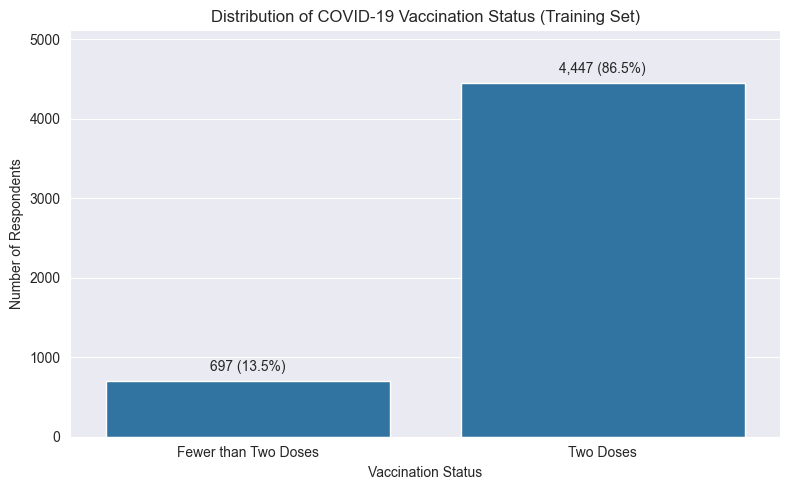

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Step 1: Create EDA dataset from training data only
eda_df = X_train.copy()
eda_df["vac_binary"] = y_train

print("EDA dataset shape:", eda_df.shape)

#Step 2: Examine target distribution
target_counts = eda_df["vac_binary"].value_counts().sort_index()
target_percentages = (
    eda_df["vac_binary"].value_counts(normalize=True)
    .sort_index() * 100)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages.round(2)})

target_summary.index = [
    "Fewer than Two Doses",
    "Two Doses"]

print("\nTarget Distribution:")
print(target_summary)

#Step 3: Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=eda_df,
    x="vac_binary",
    order=[0, 1])

ax.set_title(
    "Distribution of COVID-19 Vaccination Status (Training Set)")
ax.set_xlabel("Vaccination Status")
ax.set_ylabel("Number of Respondents")

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Fewer than Two Doses",
    "Two Doses"])

#Add counts and percentages above bars
for i, bar in enumerate(ax.patches):
    count = int(bar.get_height())
    percentage = count / len(eda_df) * 100

    ax.annotate(
        f"{count:,} ({percentage:.1f}%)",
        (bar.get_x() + bar.get_width() / 2, count),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points")

plt.ylim(0, target_counts.max() * 1.15)
plt.tight_layout()
plt.show()



#### Key Findings — Target Distribution

Among the 5,144 observations in the training set, 4,447 (86.45%) had received two doses of a COVID-19 vaccine, while 697 (13.55%) had received fewer than two doses.

This indicates substantial class imbalance. A classifier that always predicts the majority class would achieve approximately 86.45% accuracy without identifying any individuals in the minority class.

Therefore, accuracy alone may be misleading. Additional metrics, particularly recall and F1 score for individuals with fewer than two doses, should be considered when evaluating the KNN model.


           count      mean  Vaccination Rate (%)
age_group                                       
Under 30     895  0.823464             82.346369
30-44       1254  0.806220             80.622010
45-59       1150  0.853913             85.391304
60+         1845  0.930623             93.062331


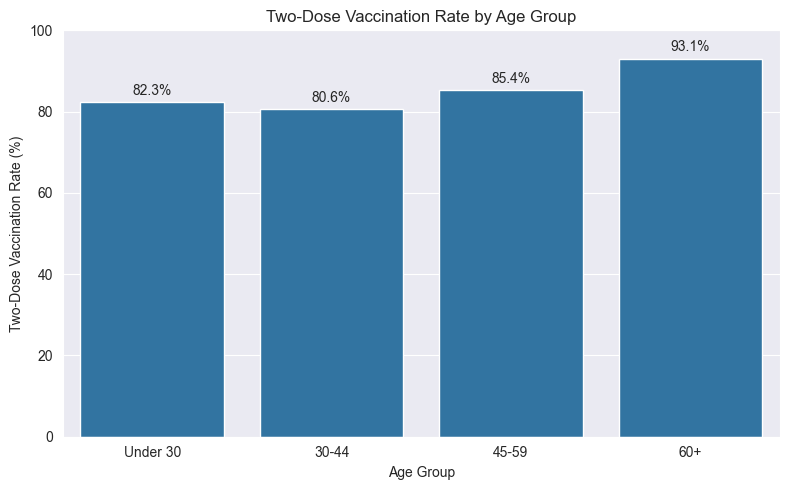

In [11]:
#EDA 2: Age vs Vaccination Status

#Create age groups
eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=[0, 29, 44, 59, float("inf")],
    labels=["Under 30", "30-44", "45-59", "60+"],
    include_lowest=True)

#Calculate vaccination rates by age group
age_summary = eda_df.groupby(
    "age_group",
    observed=True
)["vac_binary"].agg(["count", "mean"])

age_summary["Vaccination Rate (%)"] = (
    age_summary["mean"] * 100)

print(age_summary)

#Plot vaccination rate by age group
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=age_summary.reset_index(),
    x="age_group",
    y="Vaccination Rate (%)")

ax.set_title("Two-Dose Vaccination Rate by Age Group")
ax.set_xlabel("Age Group")
ax.set_ylabel("Two-Dose Vaccination Rate (%)")
ax.set_ylim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



#### Key Findings — Age vs Vaccination Status

Two-dose vaccination rates vary across age groups. Respondents aged 60 and above have the highest vaccination rate (93.06%), while those aged 30–44 have the lowest (80.62%), representing a difference of approximately 12.44 percentage points.

Although vaccination rates are generally higher among older respondents, the relationship is not strictly monotonic, as the under-30 group has a slightly higher vaccination rate (82.35%) than the 30–44 group.

These findings suggest that age may be a relevant predictor of vaccination status. From a public health perspective, younger and middle-aged groups may warrant further investigation when identifying populations with lower two-dose vaccination coverage. However, these descriptive associations do not establish causality.


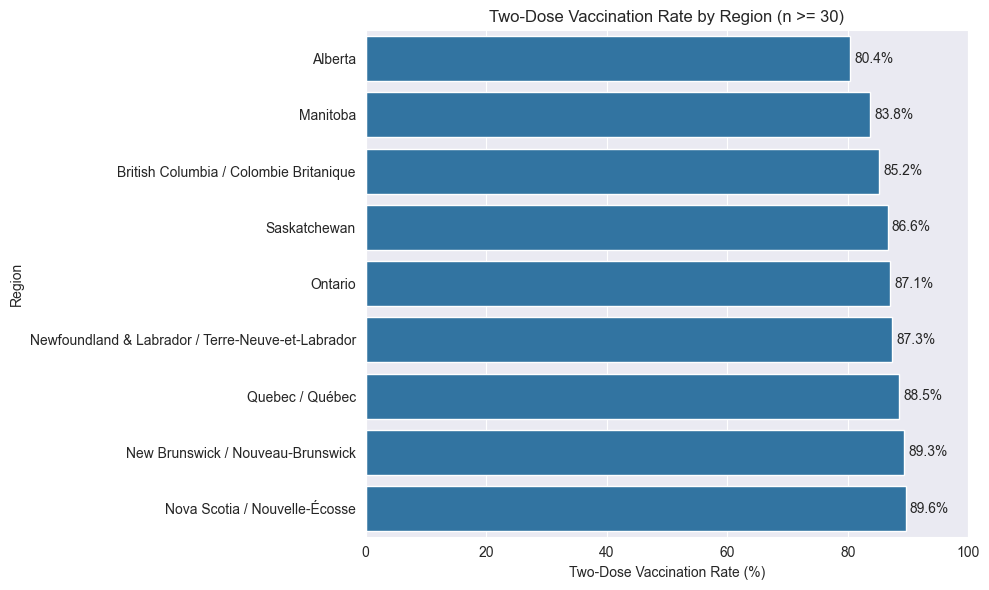

In [12]:
#EDA 3: Region vs Vaccination Status
# Exclude regions with fewer than 30 observations (I ran a full regions code before, but I found some regions only 
#include few observations)
#from visualization only

# Calculate vaccination rates by region
region_summary = eda_df.groupby(
    "region"
)["vac_binary"].agg(["count", "mean"])

region_summary["Vaccination Rate (%)"] = (
    region_summary["mean"] * 100)

region_summary = region_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)


region_plot = region_summary[
    region_summary["count"] >= 30
].copy()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=region_plot.reset_index(),
    x="Vaccination Rate (%)",
    y="region")

ax.set_title(
    "Two-Dose Vaccination Rate by Region (n >= 30)")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Region")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 3: Region vs Vaccination Status

We examine the relationship between geographic region and two-dose COVID-19 vaccination status to identify potential regional differences in vaccination coverage.

Vaccination rates are calculated as the percentage of respondents who received two doses within each region. For visualization purposes, regions with fewer than 30 observations are excluded to reduce the influence of very small sample sizes. However, these observations remain in the dataset for subsequent modeling.

#### Key Findings — Region vs Vaccination Status

Two-dose vaccination rates vary across Canadian regions. Among regions with at least 30 observations, Alberta has the lowest vaccination rate (80.35%), followed by Manitoba (83.76%). Nova Scotia has the highest rate (89.60%), while Ontario (87.06%) and Quebec (88.54%) are slightly above the overall training-set average of 86.45%.

The difference between Alberta and Nova Scotia is approximately 9.25 percentage points, suggesting a potential association between geographic location and vaccination status.

However, some regions have very small sample sizes, including Nunavut (n = 3), Yukon (n = 10), and Prince Edward Island (n = 28). Their vaccination rates should be interpreted cautiously due to sampling variability.

These findings suggest that region may be a relevant predictor for the KNN model. From a public health perspective, regional differences may help identify areas requiring further investigation or targeted vaccination outreach. However, these descriptive results are unweighted and do not establish causal relationships.


                      count      mean  Vaccination Rate (%)
employment_status                                          
Unemployed              429  0.706294             70.629371
Other                   211  0.725118             72.511848
Not working             422  0.812796             81.279621
Part time employment    512  0.814453             81.445312
Full time student       324  0.876543             87.654321
Full time employment   1745  0.883095             88.309456
Retired                1501  0.936709             93.670886


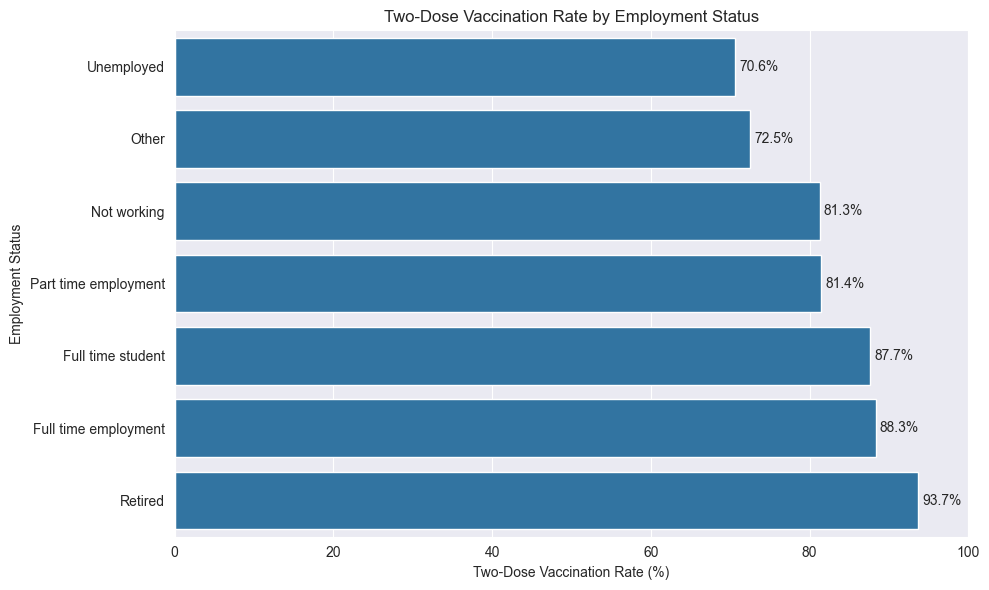

In [13]:
#EDA 4: Employment Status vs Vaccination Status

#Calculate vaccination rates by employment status
employment_summary = eda_df.groupby(
    "employment_status"
)["vac_binary"].agg(["count", "mean"])

employment_summary["Vaccination Rate (%)"] = (
    employment_summary["mean"] * 100)

#Sort by vaccination rate
employment_summary = employment_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(employment_summary)

#Plot vaccination rates by employment status
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=employment_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="employment_status")

ax.set_title(
    "Two-Dose Vaccination Rate by Employment Status")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Employment Status")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 4: Employment Status vs Vaccination Status

We examine the relationship between employment status and two-dose COVID-19 vaccination coverage to identify potential differences across socioeconomic groups.

Vaccination rates are calculated as the percentage of respondents who received two doses within each employment category.

This analysis aims to assess whether employment status may provide useful predictive information for the KNN model. Since employment status may be associated with age, observed differences will be interpreted as descriptive associations rather than causal effects.


#### Key Findings — Employment Status vs Vaccination Status

Two-dose vaccination rates differ substantially across employment groups. Retired respondents have the highest vaccination rate (93.67%), while unemployed respondents have the lowest (70.63%), representing a difference of approximately 23.04 percentage points.

Full-time employed respondents also show a relatively high vaccination rate (88.31%), compared with 81.45% among part-time employed respondents and 70.63% among unemployed respondents.

These findings suggest that employment status may provide useful predictive information for the KNN model. From a public health perspective, unemployed individuals may represent a group warranting further investigation regarding lower two-dose vaccination coverage.

However, employment status may be associated with other demographic characteristics, particularly age. The high vaccination rate among retired respondents may partly reflect their age distribution. Therefore, the observed differences should be interpreted as descriptive associations rather than causal relationships.


        count      mean  Vaccination Rate (%)
gender                                       
Male     2369  0.862811             86.281131
Female   2775  0.865946             86.594595


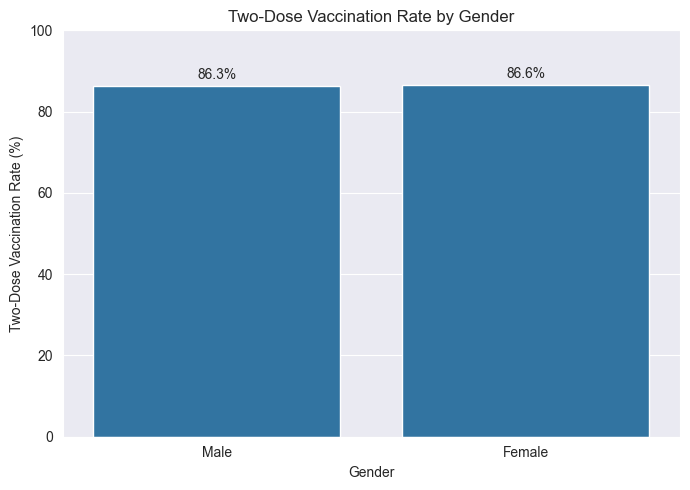

In [14]:
#EDA 5: Gender vs Vaccination Status

#Calculate vaccination rates by gender
gender_summary = eda_df.groupby(
    "gender"
)["vac_binary"].agg(["count", "mean"])

gender_summary["Vaccination Rate (%)"] = (
    gender_summary["mean"] * 100)

#Sort by vaccination rate
gender_summary = gender_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(gender_summary)

# Plot vaccination rates by gender
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_summary.reset_index(),
    x="gender",
    y="Vaccination Rate (%)")

ax.set_title("Two-Dose Vaccination Rate by Gender")
ax.set_xlabel("Gender")
ax.set_ylabel("Two-Dose Vaccination Rate (%)")
ax.set_ylim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 5: Gender vs Vaccination Status

We examine the relationship between gender and two-dose COVID-19 vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each gender category.

The objective is to identify whether vaccination coverage differs between male and female respondents and to assess whether gender may provide useful information for subsequent KNN classification.


#### Key Findings — Gender vs Vaccination Status

Two-dose vaccination rates are nearly identical between male and female respondents. Female respondents have a vaccination rate of 86.59%, compared with 86.28% among male respondents, representing a difference of only 0.31 percentage points.

This suggests that gender has a weak marginal association with vaccination status in the training sample and may offer limited standalone predictive information.

However, gender will be retained in the baseline feature set, as potential interactions with other predictors, such as age and employment status, may still provide useful information for KNN classification.



                   count      mean  Vaccination Rate (%)
household_size                                          
7                     56  0.714286             71.428571
Prefer not to say    163  0.736196             73.619632
6                    133  0.774436             77.443609
Don't know            49  0.775510             77.551020
5                    306  0.807190             80.718954
8 or more             48  0.812500             81.250000
3                    751  0.826897             82.689747
4                    710  0.838028             83.802817
1                   1099  0.886260             88.626024
2                   1829  0.913067             91.306725


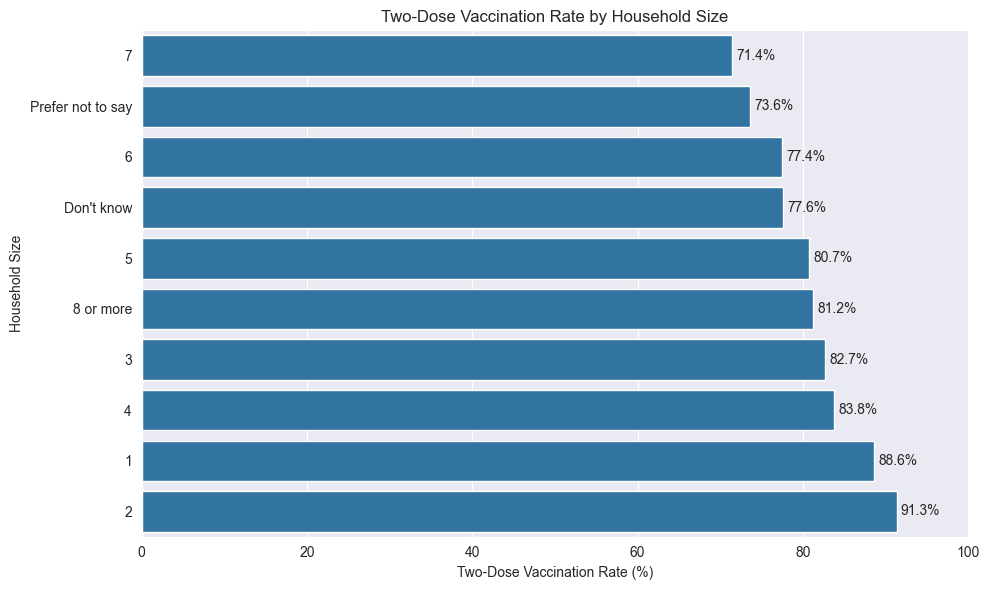

In [15]:
#EDA 6: Household Size vs Vaccination Status

# Calculate vaccination rates by household size
household_summary = eda_df.groupby(
    "household_size"
)["vac_binary"].agg(["count", "mean"])

household_summary["Vaccination Rate (%)"] = (
    household_summary["mean"] * 100)

# Sort by vaccination rate
household_summary = household_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(household_summary)

#Plot vaccination rates by household size
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=household_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="household_size")

ax.set_title("Two-Dose Vaccination Rate by Household Size")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Household Size")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()



### EDA 6: Household Size vs Vaccination Status

We examine the relationship between household size and two-dose COVID-19 vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each household size category.

The objective is to determine whether household composition may be associated with vaccination status and whether household size may provide useful predictive information for KNN classification.

Special attention is given to categories with small sample sizes and non-numeric responses, such as "Don't know" and "Prefer not to say."


#### Key Findings — Household Size vs Vaccination Status

Two-dose vaccination rates vary across household sizes. Respondents living in two-person households have the highest vaccination rate (91.31%), followed by those living alone (88.63%).

Vaccination rates are generally lower among respondents in larger households. For example, the rate decreases to 80.72% for five-person households, 77.44% for six-person households, and 71.43% for seven-person households.

However, this relationship is not strictly monotonic, and larger household categories have relatively small sample sizes. The observed differences may also reflect demographic factors such as age and employment status.

Non-numeric responses, including "Don't know" and "Prefer not to say", were retained as separate categories rather than treated as household sizes.

These findings suggest that household size may contain useful predictive information for the KNN model, although further analysis is needed to determine whether its association with vaccination status remains after accounting for other characteristics.


                    count      mean  Vaccination Rate (%)
household_children                                       
Don't know              8  0.625000             62.500000
3                     195  0.748718             74.871795
Prefer not to say      74  0.756757             75.675676
4                     136  0.779412             77.941176
5 or more              83  0.783133             78.313253
1                     660  0.812121             81.212121
2                     559  0.835420             83.542039
0                    3429  0.894138             89.413823


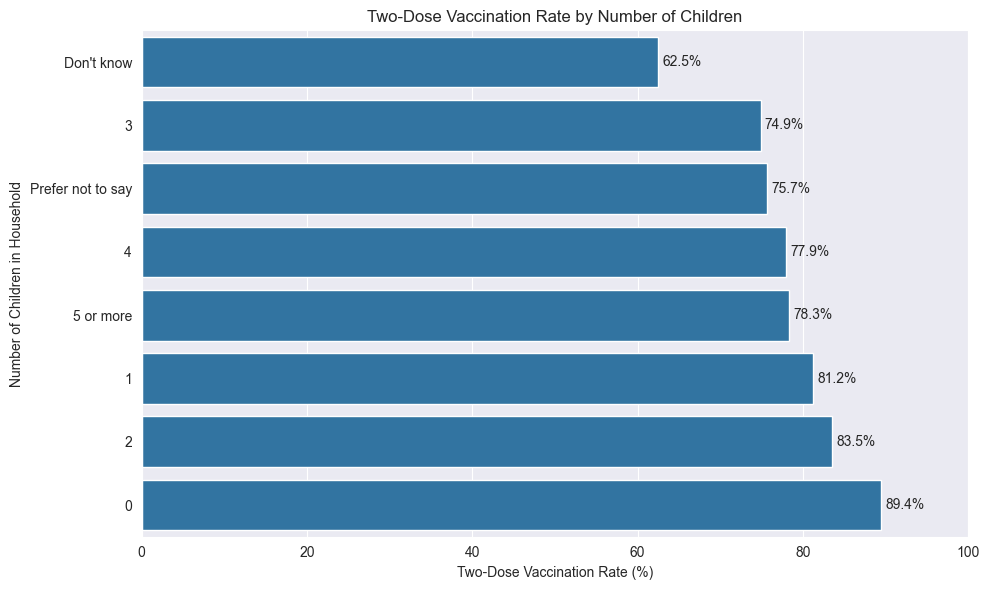

In [16]:
#EDA 7: Household Children vs Vaccination Status

#Calculate vaccination rates by number of children
children_summary = eda_df.groupby(
    "household_children"
)["vac_binary"].agg(["count", "mean"])

children_summary["Vaccination Rate (%)"] = (
    children_summary["mean"] * 100)

#Sort by vaccination rate
children_summary = children_summary.sort_values(
    "Vaccination Rate (%)",
    ascending=True)

print(children_summary)

# Plot vaccination rates by number of children
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=children_summary.reset_index(),
    x="Vaccination Rate (%)",
    y="household_children")

ax.set_title(
    "Two-Dose Vaccination Rate by Number of Children")
ax.set_xlabel("Two-Dose Vaccination Rate (%)")
ax.set_ylabel("Number of Children in Household")
ax.set_xlim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 7: Household Children vs Vaccination Status

We examine the relationship between the number of children in a household and two-dose COVID-19 vaccination status using the training dataset.

Vaccination rates are calculated as the percentage of respondents who received two doses within each household children category.

The objective is to investigate whether household composition, particularly the presence and number of children, is associated with vaccination status and whether this variable may provide additional predictive information for KNN classification.

Categories with small sample sizes and non-numeric responses will be interpreted cautiously.


#### Key Findings — Household Children vs Vaccination Status

Two-dose vaccination rates vary across households with different numbers of children. Respondents living in households without children have the highest vaccination rate (89.41%), while those living in households with three children have a substantially lower rate (74.87%), representing a difference of approximately 14.54 percentage points.

However, vaccination rates do not decrease consistently as the number of children increases. For example, households with two children have a higher vaccination rate (83.54%) than those with one child (81.21%).

These findings suggest that household composition may be associated with vaccination status. However, the relationship may partly reflect differences in age and employment status across households.

Categories with very small sample sizes, particularly "Don't know" (n = 8), should be interpreted cautiously.

Household children will be retained as a baseline predictor, although its additional predictive value beyond household size and other demographic variables remains to be evaluated.



                count      mean  Vaccination Rate (%)
cantril_ladder                                       
0                  90  0.722222             72.222222
1                  81  0.802469             80.246914
2                 150  0.886667             88.666667
3                 303  0.805281             80.528053
4                 371  0.822102             82.210243
5                 730  0.842466             84.246575
6                 754  0.862069             86.206897
7                1131  0.883289             88.328912
8                1010  0.918812             91.881188
9                 336  0.866071             86.607143
10                188  0.808511             80.851064


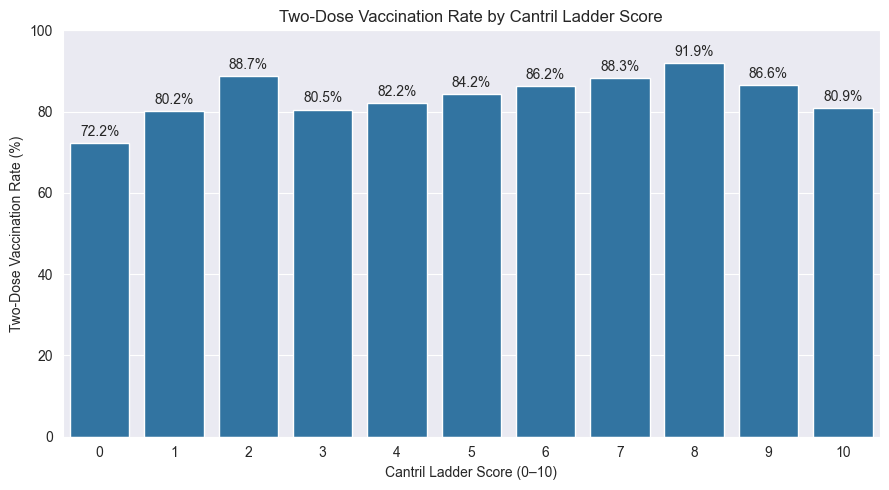

In [17]:
#EDA 8: Cantril Ladder vs Vaccination Status

#Calculate vaccination rate by Cantril Ladder score
cantril_summary = eda_df.groupby(
    "cantril_ladder"
)["vac_binary"].agg(["count", "mean"])

cantril_summary["Vaccination Rate (%)"] = (
    cantril_summary["mean"] * 100)

print(cantril_summary)

#Plot vaccination rate by Cantril Ladder score
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=cantril_summary.reset_index(),
    x="cantril_ladder",
    y="Vaccination Rate (%)")

ax.set_title(
    "Two-Dose Vaccination Rate by Cantril Ladder Score")
ax.set_xlabel("Cantril Ladder Score (0–10)")
ax.set_ylabel("Two-Dose Vaccination Rate (%)")
ax.set_ylim(0, 100)

#Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### EDA 8: Cantril Ladder vs Vaccination Status

We examine the relationship between respondents' Cantril Ladder scores (a self-reported measure of life evaluation ranging from 0 to 10) and two-dose COVID-19 vaccination status.

Vaccination rates are calculated for each Cantril Ladder score to explore whether subjective well-being is associated with vaccination coverage.

The analysis aims to assess whether Cantril Ladder may provide additional predictive information for KNN classification.


#### Key Findings — Cantril Ladder vs Vaccination Status

Two-dose vaccination rates vary across Cantril Ladder scores, suggesting a potential association between subjective life evaluation and vaccination status.

Vaccination rates generally increase from 80.53% at a Cantril Ladder score of 3 to 91.88% at a score of 8. However, the relationship is not strictly monotonic, as vaccination rates decline to 86.61% at score 9 and 80.85% at score 10.

Sample sizes also vary substantially across scores, with fewer observations at the extremes. Therefore, these differences should be interpreted cautiously.

The results suggest that Cantril Ladder may provide useful predictive information for KNN classification, although its incremental predictive value remains to be evaluated through cross-validation.


Vaccination Rates by Age Group and Employment Status:
age_group    employment_status  count     mean  Vaccination Rate (%)
 Under 30 Full time employment    306 0.866013             86.601307
 Under 30    Full time student    258 0.903101             90.310078
 Under 30          Not working     55 0.581818             58.181818
 Under 30                Other     65 0.738462             73.846154
 Under 30 Part time employment    108 0.796296             79.629630
 Under 30              Retired      8 0.750000             75.000000
 Under 30           Unemployed     95 0.705263             70.526316
    30-44 Full time employment    742 0.870620             87.061995
    30-44    Full time student     58 0.741379             74.137931
    30-44          Not working    106 0.726415             72.641509
    30-44                Other     61 0.655738             65.573770
    30-44 Part time employment    118 0.779661             77.966102
    30-44              Retired      8 0.750000   

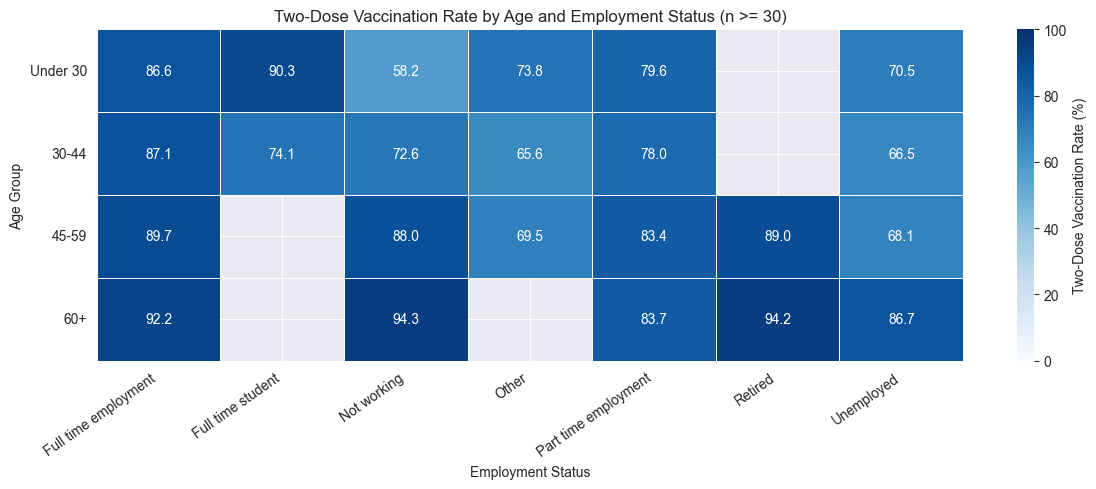

In [18]:
#EDA 9: Age × Employment Status vs Vaccination Status

#Step 1: Create age groups (if not already created)
eda_df["age_group"] = pd.cut(
    eda_df["age"],
    bins=[0, 29, 44, 59, float("inf")],
    labels=["Under 30", "30-44", "45-59", "60+"],
    include_lowest=True)

#Step 2: Calculate vaccination rates for each combination
age_employment_summary = eda_df.groupby(
    ["age_group", "employment_status"],
    observed=True
)["vac_binary"].agg(["count", "mean"]).reset_index()

age_employment_summary["Vaccination Rate (%)"] = (
    age_employment_summary["mean"] * 100)

print("Vaccination Rates by Age Group and Employment Status:")
print(age_employment_summary.to_string(index=False))


#Step 3: Create cross-tabulation of vaccination rates
rate_table = pd.crosstab(
    eda_df["age_group"],
    eda_df["employment_status"],
    values=eda_df["vac_binary"],
    aggfunc="mean") * 100

print("\nVaccination Rate Cross-tabulation (%):")
print(rate_table.round(2))


#Step 4: Create cross-tabulation of sample sizes
count_table = pd.crosstab(
    eda_df["age_group"],
    eda_df["employment_status"])

print("\nSample Size Cross-tabulation:")
print(count_table)


#Step 5: Mask groups with fewer than 30 observations
mask = count_table.reindex(
    index=rate_table.index,
    columns=rate_table.columns) < 30


#Step 6: Visualize vaccination rates using a heatmap
plt.figure(figsize=(12, 5))

sns.heatmap(
    rate_table,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    mask=mask,
    linewidths=0.5,
    cbar_kws={"label": "Two-Dose Vaccination Rate (%)"})

plt.title(
    "Two-Dose Vaccination Rate by Age and Employment Status (n >= 30)")
plt.xlabel("Employment Status")
plt.ylabel("Age Group")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### EDA 9: Age × Employment Status vs Vaccination Status

We conduct a multivariate exploratory analysis to investigate whether differences in two-dose vaccination rates across employment groups persist within the same age categories.

Vaccination rates are calculated for each combination of age group and employment status using the training dataset.

Previous EDA findings indicated that older and retired respondents had higher vaccination rates, while unemployed respondents had lower rates. This analysis examines whether these patterns may partly reflect differences in age composition.

To avoid misleading interpretations from very small samples, combinations with fewer than 30 observations are masked in the heatmap. All observations remain in the dataset for subsequent modeling.


#### Key Findings — Age × Employment Status vs Vaccination Status

The multivariate analysis indicates that differences in two-dose vaccination rates across employment groups persist within age categories.

Full-time employed respondents consistently have higher vaccination rates than unemployed respondents across all four age groups. The differences are particularly pronounced among respondents aged 30–44 (87.06% vs. 66.46%) and 45–59 (89.75% vs. 68.14%), representing gaps of 20.60 and 21.61 percentage points, respectively.

Vaccination rates also generally increase with age among full-time employed respondents, from 86.60% for those under 30 to 92.22% for those aged 60 and above.

These findings suggest that both age and employment status may provide useful predictive information and that employment-related differences cannot be fully explained by the broad age categories used in this analysis.

Certain population segments, particularly unemployed respondents aged 30–59, exhibit relatively low vaccination rates and may warrant further investigation from a public health perspective.

To reduce misleading interpretations, age-employment combinations with fewer than 30 observations were masked in the heatmap but retained in the underlying dataset. The results are descriptive, unweighted, and do not establish causal relationships.



In [19]:
#Step 10: Export Cleaned Baseline Dataset

#Select baseline predictors and binary target
baseline_data = df_clean[
    features + ["vac_binary"]
].copy()

#Verify dataset structure
print("Final dataset shape:", baseline_data.shape)

print("\nMissing values:")
print(baseline_data.isna().sum())

print("\nTarget distribution:")
print(baseline_data["vac_binary"].value_counts())

# Export to CSV
baseline_data.to_csv(
    "covid_cleaned_baseline.csv",
    index=False)

print("\nBaseline dataset exported successfully.")


Final dataset shape: (6430, 8)

Missing values:
age                   0
gender                0
region                0
employment_status     0
household_size        0
household_children    0
cantril_ladder        0
vac_binary            0
dtype: int64

Target distribution:
vac_binary
1    5559
0     871
Name: count, dtype: int64

Baseline dataset exported successfully.


In [20]:
df2 = pd.read_csv(
    "covid_cleaned_baseline.csv",
    low_memory=False)
df2

,age,gender,region,employment_status,household_size,household_children,cantril_ladder,vac_binary
0,52,Female,Quebec / Québec,Full time employment,4,0,9,1
1,51,Female,British Columbia / Colombie Britanique,Full time employment,2,0,6,1
2,57,Female,Quebec / Québec,Part time employment,1,0,1,1
3,64,Female,Quebec / Québec,Retired,1,0,6,1
4,45,Male,Quebec / Québec,Full time employment,5,5 or more,5,1
...,...,...,...,...,...,...,...,...
6425,19,Male,Ontario,Full time student,2,0,7,1
6426,21,Male,Ontario,Other,4,Prefer not to say,6,0
6427,28,Male,Ontario,Unemployed,5,5 or more,2,1
6428,21,Male,Ontario,Full time student,2,0,7,0


## Choice of k and Model Tuning — Balanced Accuracy

Our goal is to predict whether a respondent received at least two COVID-19 vaccine doses (Class 1) or fewer than two doses (Class 0). Because Class 1 makes up most of the dataset, we use **balanced accuracy** to select the model. Balanced accuracy gives equal importance to the recall of both classes, rather than mainly rewarding correct predictions for the larger class.

We choose hyperparameters using 5-fold cross-validation on the training set only. We also report regular accuracy, precision, recall, and F1 to better understand the model's strengths and limitations.

### 1. Preprocessing and cross-validation

KNN compares observations using distance. We standardize numerical variables, one-hot encode categorical variables, and fill missing values within the pipeline. This keeps preprocessing separate within each training fold.

We use stratified 5-fold cross-validation to keep the proportions of Class 0 and Class 1 similar across folds. The test set is kept separate until final evaluation.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["age", "cantril_ladder"]
categorical_features = ["gender", "region", "employment_status", "household_size", "household_children"]
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_pipeline, numeric_features), ("categorical", categorical_pipeline, categorical_features)])
pipeline = Pipeline([("preprocessor", preprocessor), ("knn", KNeighborsClassifier())])
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Balanced accuracy selects the model; the other scores help explain its performance.
scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy",
    "f1_class1": "f1",
    "f1_class0": make_scorer(f1_score, pos_label=0)
}

### 2. Hyperparameter tuning using 5-fold CV

We compare **k = 1 to 51** and two voting methods: `uniform` and `distance`. This gives 102 combinations. GridSearchCV evaluates each combination using 5-fold cross-validation and selects the one with the highest mean **balanced accuracy**.

We also record training scores and the performance of both classes to understand how changing k affects the model.

In [22]:
k_values = np.arange(1, 52)
param_grid = {"knn__n_neighbors": k_values, "knn__weights": ["uniform", "distance"]}
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="balanced_accuracy",
    cv=kfold,
    return_train_score=True,
    n_jobs=-1
)
grid_result = grid.fit(X_train, y_train)
print("Best parameters (balanced accuracy):", grid_result.best_params_)
print("Best mean CV balanced accuracy:", round(grid_result.best_score_, 4))

Best parameters (balanced accuracy): {'knn__n_neighbors': np.int64(2), 'knn__weights': 'uniform'}
Best mean CV balanced accuracy: 0.6484


### 3. Cross-Validation Results and Model Selection

We select the model with the highest average **balanced accuracy** across the five validation folds. This metric is the average recall of Class 0 and Class 1, so both vaccination groups matter equally.

We also show the regular accuracy and F1 scores for each class. Since most respondents are in Class 1, regular accuracy can be high even if the model misses many Class 0 respondents.

In [23]:
results = pd.DataFrame(grid_result.cv_results_)
summary = results[[
    "param_knn__n_neighbors", "param_knn__weights",
    "mean_train_balanced_accuracy", "mean_test_balanced_accuracy", "std_test_balanced_accuracy",
    "mean_test_accuracy", "mean_test_f1_class1", "mean_test_f1_class0"
]].copy()
summary.columns = [
    "k", "weights", "Train Balanced Accuracy", "CV Balanced Accuracy",
    "CV SD", "CV Accuracy", "CV F1 Class 1", "CV F1 Class 0"
]
summary["k"] = summary["k"].astype(int)
summary = summary.sort_values("CV Balanced Accuracy", ascending=False)
selected_row = summary.loc[grid_result.best_index_]
print("Top 15 candidate settings by CV balanced accuracy:")
display(summary.head(15).round(4))
print("Selected candidate:")
display(summary.loc[[grid_result.best_index_]].round(4))

# An always-Class-1 model would get balanced accuracy = 0.5.
print("Always-Class-1 baseline balanced accuracy: 0.5000")

Top 15 candidate settings by CV balanced accuracy:


,k,weights,Train Balanced Accuracy,CV Balanced Accuracy,CV SD,CV Accuracy,CV F1 Class 1,CV F1 Class 0
2,2,uniform,0.9543,0.6484,0.0164,0.7823,0.8685,0.3671
3,2,distance,0.9953,0.6338,0.0089,0.8334,0.9040,0.3698
0,1,uniform,0.9880,0.6337,0.0098,0.8373,0.9065,0.3717
1,1,distance,0.9880,0.6337,0.0098,0.8373,0.9065,0.3717
5,3,distance,0.9938,0.6083,0.0064,0.8468,0.9135,0.3322
6,4,uniform,0.7487,0.6059,0.0134,0.8353,0.9062,0.3240
7,4,distance,0.9938,0.6033,0.0089,0.8495,0.9153,0.3234
11,6,distance,0.9938,0.5942,0.0089,0.8579,0.9208,0.3070
9,5,distance,0.9938,0.5903,0.0085,0.8554,0.9194,0.2981
4,3,uniform,0.7159,0.5806,0.0094,0.8470,0.9145,0.2757


Selected candidate:


,k,weights,Train Balanced Accuracy,CV Balanced Accuracy,CV SD,CV Accuracy,CV F1 Class 1,CV F1 Class 0
2,2,uniform,0.9543,0.6484,0.0164,0.7823,0.8685,0.3671


Always-Class-1 baseline balanced accuracy: 0.5000


### 4. Accuracy, Precision, Recall, F1, and Balanced Accuracy

We calculate these metrics using out-of-fold predictions on the training data:

- **Accuracy:** the percentage of all predictions that are correct.
- **Precision (Class 1):** of those predicted to have at least two doses, how many actually did.
- **Recall (Class 1):** of those who actually had at least two doses, how many we identified.
- **F1 (Class 1):** combines Class 1 precision and recall.
- **Balanced accuracy:** the average recall of Class 0 and Class 1.

We use **balanced accuracy for tuning** because the two classes have very different sizes. We still report F1 and Class 0 recall because they show whether the model performs well beyond the majority class. These are training-set CV diagnostics, not final test scores.

In [24]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score
)

metric_model = clone(grid_result.best_estimator_)
cv_predictions = cross_val_predict(metric_model, X_train, y_train, cv=kfold, n_jobs=-1)
metric_table = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy", "Precision (Class 1)",
               "Recall (Class 1)", "F1 (Class 1)",
               "Recall (Class 0)", "F1 (Class 0)"],
    "Out-of-fold training estimate": [
        accuracy_score(y_train, cv_predictions),
        balanced_accuracy_score(y_train, cv_predictions),
        precision_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        recall_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        f1_score(y_train, cv_predictions, pos_label=1, zero_division=0),
        recall_score(y_train, cv_predictions, pos_label=0, zero_division=0),
        f1_score(y_train, cv_predictions, pos_label=0, zero_division=0)
    ]
})
display(metric_table.round(4))
# The parameters were selected using the same training sample, so these are diagnostics,
# not an independent estimate of final performance.

,Metric,Out-of-fold training estimate
0,Accuracy,0.7823
1,Balanced Accuracy,0.6484
2,Precision (Class 1),0.9084
3,Recall (Class 1),0.8320
4,F1 (Class 1),0.8685
5,Recall (Class 0),0.4648
6,F1 (Class 0),0.3665


### 5. Choice of k: balancing noise and predictor information

A small k uses only a few nearby observations, so it can capture local differences but may also be sensitive to noise. A large k gives smoother predictions, but with our imbalanced data it can favor Class 1 and miss more Class 0 respondents.

We compare training and cross-validation balanced accuracy to check for possible overfitting. We also compare recall for both classes. **k = 2** is the best choice under our balanced-accuracy criterion, based on the CV results. However, a small k may still be sensitive to individual observations, so we should not claim that it eliminates overfitting.

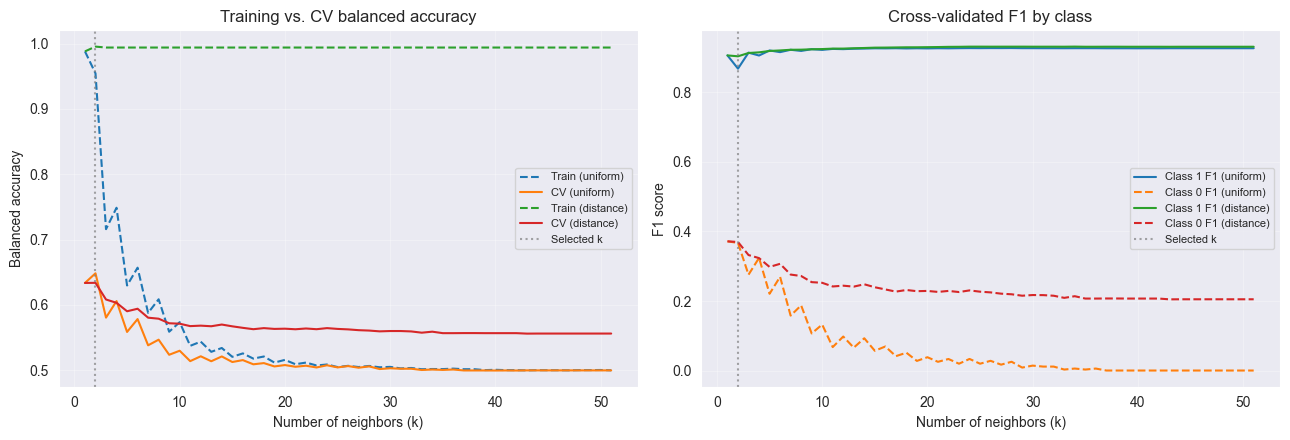

Selected k: 2
Selected weights: uniform
Selected CV balanced accuracy: 0.6484
Selected CV accuracy: 0.7823
Selected Class 0 CV F1: 0.3671
Train–CV balanced accuracy gap: 0.3059


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for weight in ["uniform", "distance"]:
    subset = summary[summary["weights"] == weight].sort_values("k")
    axes[0].plot(subset["k"], subset["Train Balanced Accuracy"], "--", label=f"Train ({weight})")
    axes[0].plot(subset["k"], subset["CV Balanced Accuracy"], label=f"CV ({weight})")
    axes[1].plot(subset["k"], subset["CV F1 Class 1"], label=f"Class 1 F1 ({weight})")
    axes[1].plot(subset["k"], subset["CV F1 Class 0"], "--", label=f"Class 0 F1 ({weight})")
for ax in axes:
    ax.axvline(int(selected_row["k"]), color="gray", linestyle=":", alpha=0.7, label="Selected k")
    ax.set_xlabel("Number of neighbors (k)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Balanced accuracy")
axes[1].set_ylabel("F1 score")
axes[0].set_title("Training vs. CV balanced accuracy")
axes[1].set_title("Cross-validated F1 by class")
plt.tight_layout()
plt.show()

print("Selected k:", int(selected_row["k"]))
print("Selected weights:", selected_row["weights"])
print("Selected CV balanced accuracy:", round(selected_row["CV Balanced Accuracy"], 4))
print("Selected CV accuracy:", round(selected_row["CV Accuracy"], 4))
print("Selected Class 0 CV F1:", round(selected_row["CV F1 Class 0"], 4))
print("Train–CV balanced accuracy gap:", round(selected_row["Train Balanced Accuracy"] - selected_row["CV Balanced Accuracy"], 4))

### 6. Additional experiments

We also explored removing individual predictors and oversampling Class 0 in separate experiments. These experiments were originally evaluated using **Class 0 F1**, not balanced accuracy, so their results cannot be directly compared with the current grid search.

We keep the original seven predictors and do not use oversampling in the final model. This keeps the comparison of k and voting weights consistent.

### 7. Final Model Selection and Interpretation

We used stratified 5-fold cross-validation to compare k values from 1 to 51 and two voting methods. We selected the model based on **balanced accuracy** because our dataset has many more Class 1 respondents than Class 0 respondents.

**The best k was 2.** This means that using a small number of nearby observations gave the best balance of recall across the two classes in our cross-validation results. When k became larger, the model tended to favor Class 1, making it harder to identify respondents who received fewer than two vaccine doses.

A small k can be more sensitive to noise, so k = 2 is not automatically free from overfitting. We use the cross-validation results, rather than training accuracy alone, to support this choice. We also report Class 0 and Class 1 F1 scores to show the limits of the model.

The model may help the Public Health Agency of Canada study vaccination patterns. However, it should not be used alone to identify people who need additional vaccination outreach, especially if Class 0 recall remains low on the test set.

Final k: 2
Final weights: uniform
Exploratory threshold comparison (training folds only):


,Threshold,OOF Balanced Accuracy,OOF F1 Class 1,OOF F1 Class 0
0,0.50,0.5594,0.9265,0.2192
1,0.55,0.6484,0.8685,0.3665
2,0.60,0.6484,0.8685,0.3665
3,0.65,0.6484,0.8685,0.3665
4,0.70,0.6484,0.8685,0.3665
5,0.75,0.6484,0.8685,0.3665
6,0.80,0.6484,0.8685,0.3665
7,0.85,0.6484,0.8685,0.3665
8,0.90,0.6484,0.8685,0.3665


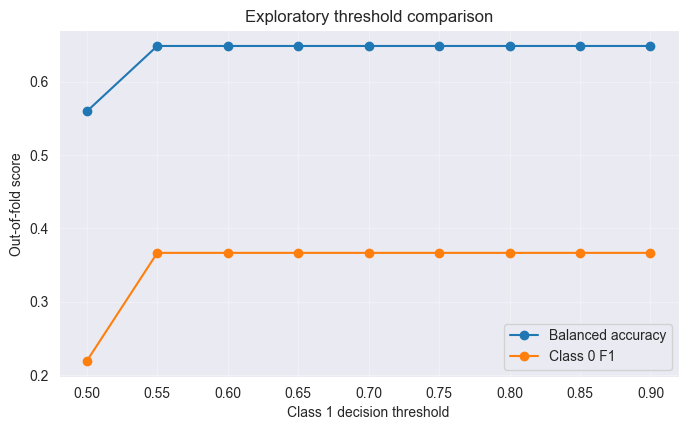

Final prediction rule: default KNN voting


In [26]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, balanced_accuracy_score

# Fit the CV-selected model using the full training set only.
best_model = clone(grid_result.best_estimator_)
best_model.fit(X_train, y_train)
print("Final k:", best_model.named_steps["knn"].n_neighbors)
print("Final weights:", best_model.named_steps["knn"].weights)

# Optional threshold exploration: diagnostics on training folds only.
cv_probs = cross_val_predict(clone(best_model), X_train, y_train,
                             cv=kfold, method="predict_proba", n_jobs=-1)
class1_col = list(best_model.classes_).index(1)
cv_prob_class1 = cv_probs[:, class1_col]
threshold_rows = []
for threshold in np.round(np.arange(0.50, 0.91, 0.05), 2):
    pred = (cv_prob_class1 >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "OOF Balanced Accuracy": balanced_accuracy_score(y_train, pred),
        "OOF F1 Class 1": f1_score(y_train, pred, pos_label=1, zero_division=0),
        "OOF F1 Class 0": f1_score(y_train, pred, pos_label=0, zero_division=0)
    })
threshold_df = pd.DataFrame(threshold_rows)
print("Exploratory threshold comparison (training folds only):")
display(threshold_df.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(threshold_df["Threshold"], threshold_df["OOF Balanced Accuracy"], marker="o", label="Balanced accuracy")
plt.plot(threshold_df["Threshold"], threshold_df["OOF F1 Class 0"], marker="o", label="Class 0 F1")
plt.xlabel("Class 1 decision threshold")
plt.ylabel("Out-of-fold score")
plt.title("Exploratory threshold comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# The final model uses KNN's default predict() rule; threshold analysis is diagnostic only.
print("Final prediction rule: default KNN voting")